# Chapter 14 · Gaussian conditioning: interactive demos

Companion to Chapter 14 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/14-gaussian-conditioning.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.gaussian_conditioning import (bivariate_conditional, conditional_law, conditional_independence_graph,
                                             partial_correlations, partial_sums_cov, sample_gaussian, slab_mask,
                                             slab_moments)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
CMAP = LinearSegmentedColormap.from_list("gc", [GOLD, "white", COBALT])
use_style()

## 1. The law of $X$ given $Y=y$ in a Gaussian pair

For $(X,Y)$ Gaussian with $\sigma_Y>0$, the variable $Z=X-aY$ with $a=c_{XY}/\sigma_Y^2$ is independent of $Y$, and
$X\mid Y=y\sim\mathcal N(m(y),\sigma^2)$ with $m(y)=\mu_X-\rho\frac{\sigma_X}{\sigma_Y}(\mu_Y-y)$ and $\sigma^2=\sigma_X^2(1-\rho^2)$
(Theorem 14.1). Since $\mathbb P(Y=y)=0$, the simulation conditions on a thin slab $|Y-y|<h$ (Remark 14.3). Left: draws of
$(Y,X)$, the line $m$ and the band $m\pm2\sigma$, the slab in green. Right: the values of $X$ in the slab against
$\mathcal N(m(y),\sigma^2)$ and against the law of $X$. The slab average of $X$ is compared with $m(y)$ and with $m$ at the slab
average of $Y$, which is exact because $m$ is affine.

slab average of X: 0.7114 +- 0.0101;  m(y0) = 0.7000;  m(slab average of Y) = 0.6997
slab variance of X: 0.5121;  sigma^2 = 0.5100


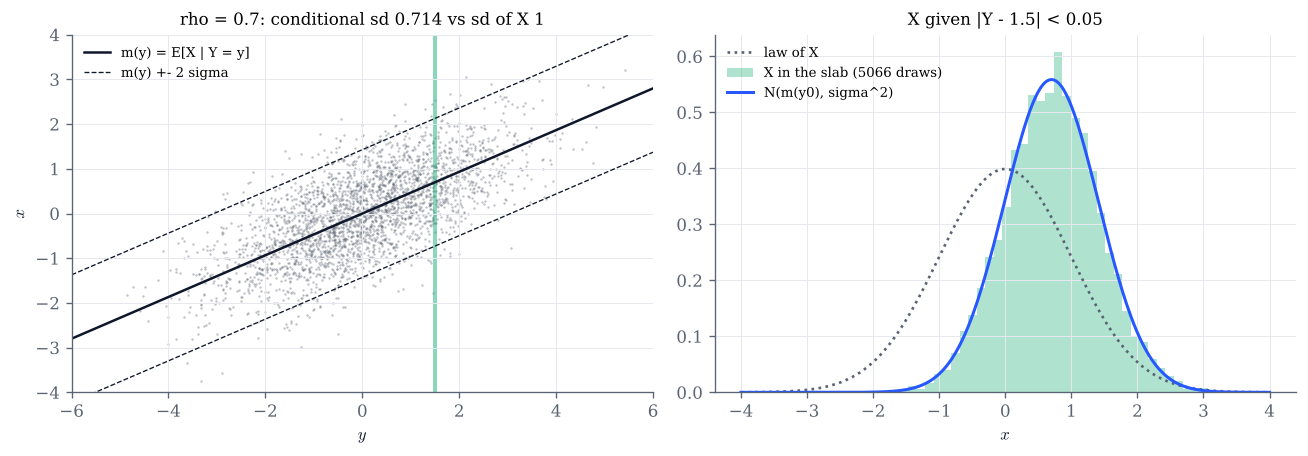

In [3]:
def bivariate_demo(rho=0.7, sigma_x=1.0, sigma_y=1.5, y0=1.5, h=0.05, log10_n=5.5, seed=2026):
    n = int(10 ** log10_n)
    mx, my = 0.0, 0.0
    C = np.array([[sigma_x ** 2, rho * sigma_x * sigma_y], [rho * sigma_x * sigma_y, sigma_y ** 2]])
    s = sample_gaussian([mx, my], C, n, seed=seed)
    m, s2 = bivariate_conditional(y0, mx, my, sigma_x ** 2, sigma_y ** 2, rho * sigma_x * sigma_y)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9))
    a1.scatter(s[:3000, 1], s[:3000, 0], s=2, color=GREY, alpha=0.4, lw=0)
    t = np.linspace(-4 * sigma_y, 4 * sigma_y, 50)
    mt, _ = bivariate_conditional(t, mx, my, sigma_x ** 2, sigma_y ** 2, rho * sigma_x * sigma_y)
    a1.plot(t, mt, color=INK, lw=1.5, label="m(y) = E[X | Y = y]")
    a1.plot(t, mt + 2 * np.sqrt(s2), color=INK, lw=0.8, ls="--", label="m(y) +- 2 sigma")
    a1.plot(t, mt - 2 * np.sqrt(s2), color=INK, lw=0.8, ls="--")
    a1.axvspan(y0 - h, y0 + h, color=GREEN, alpha=0.5, lw=0)
    a1.set(xlim=(t[0], t[-1]), ylim=(-4 * sigma_x, 4 * sigma_x), xlabel="$y$", ylabel="$x$",
           title=f"rho = {rho:g}: conditional sd {np.sqrt(s2):.3f} vs sd of X {sigma_x:g}")
    a1.legend(fontsize=8, loc="upper left")
    xs = np.linspace(-4 * sigma_x, 4 * sigma_x, 400)
    a2.plot(xs, stats.norm.pdf(xs, mx, sigma_x), color=GREY, ls=":", label="law of X")
    sel = s[slab_mask(s, [1], [y0], h), 0]
    if sel.size > 1:
        a2.hist(sel, bins=40, density=True, color=GREEN, alpha=0.35, label=f"X in the slab ({sel.size} draws)")
        e = slab_moments(s, [1], [y0], h)
        mbar, _ = bivariate_conditional(e.given_mean[0], mx, my, sigma_x ** 2, sigma_y ** 2, rho * sigma_x * sigma_y)
        print(f"slab average of X: {e.mean[0]:.4f} +- {e.se[0]:.4f};  m(y0) = {float(m):.4f};  "
              f"m(slab average of Y) = {float(mbar):.4f}")
        print(f"slab variance of X: {e.cov[0, 0]:.4f};  sigma^2 = {s2:.4f}")
    if s2 > 0:
        a2.plot(xs, stats.norm.pdf(xs, m, np.sqrt(s2)), color=COBALT, lw=1.8, label=f"N(m(y0), sigma^2)")
    a2.set(xlabel="$x$", title=f"X given |Y - {y0:g}| < {h:g}")
    a2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

bivariate_demo()

In [4]:
# Explore: the conditional variance does not move with y0; it shrinks by the factor 1 - rho^2. Try rho = 0 and rho = 0.99.
interact(bivariate_demo,
         rho=FloatSlider(value=0.7, min=-0.99, max=0.99, step=0.01, continuous_update=False, description="rho"),
         sigma_x=FloatSlider(value=1.0, min=0.2, max=3.0, step=0.1, continuous_update=False, description="sigma_X"),
         sigma_y=FloatSlider(value=1.5, min=0.2, max=3.0, step=0.1, continuous_update=False, description="sigma_Y"),
         y0=FloatSlider(value=1.5, min=-4.0, max=4.0, step=0.1, continuous_update=False, description="y0"),
         h=FloatSlider(value=0.05, min=0.005, max=1.0, step=0.005, continuous_update=False, description="half-width h"),
         log10_n=FloatSlider(value=5.5, min=4.0, max=6.5, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 2. Conditioning partial sums: a discrete Brownian bridge

Let $S_k=X_1+\dots+X_k$, $k=1,\dots,N$, with $X_i$ independent $\mathcal N(0,1)$: $\operatorname{cov}(S_k,S_l)=\min(k,l)$. The block
formulas (Theorem 14.5) give the law of the other partial sums given some of them. Given $S_N=s$ the mean is the straight
line $ks/N$ and the variance $k(N-k)/N$ (Exercise 14.8): a discrete Brownian bridge. Conditioning also on an intermediate
value pins the path there too. The band is the conditional mean $\pm2$ conditional standard deviations; the thin lines are
exact draws from the conditional law. For the bridge, the green dots average the paths whose $S_N$ falls within $h$ of $s$,
out of unconditioned draws.

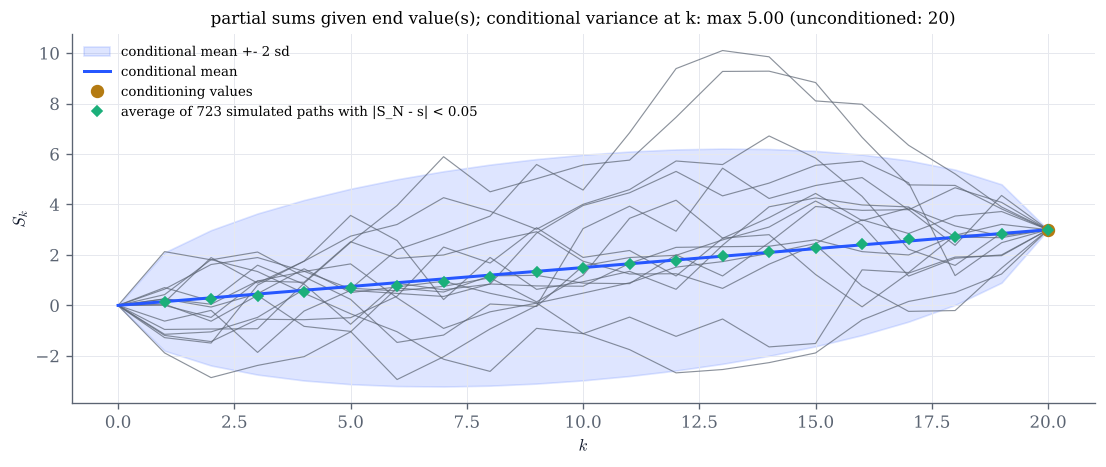

In [5]:
def bridge_demo(N=20, pin="end", s=3.0, s_mid=-2.0, paths=15, h=0.05, log10_n=5.0, seed=2026):
    C = partial_sums_cov(N)
    k = np.arange(1, N + 1)
    given = [N - 1] if pin == "end" else ([N // 2 - 1] if pin == "middle" else [N // 2 - 1, N - 1])
    vals = [s] if pin == "end" else ([s_mid] if pin == "middle" else [s_mid, s])
    r = conditional_law(None, C, given, vals)
    mean, sd = np.zeros(N), np.zeros(N)
    mean[r.target], sd[r.target] = r.mean, np.sqrt(np.clip(np.diag(r.cov), 0, None))
    mean[given] = vals
    fig, ax = plt.subplots(figsize=(11, 4))
    draws = sample_gaussian(r.mean, r.cov, paths, seed=seed)
    for d in draws:
        y = np.zeros(N)
        y[r.target], y[given] = d, vals
        ax.plot(np.r_[0, k], np.r_[0, y], color=GREY, lw=0.7, alpha=0.7)
    ax.fill_between(np.r_[0, k], np.r_[0, mean - 2 * sd], np.r_[0, mean + 2 * sd], color=COBALT, alpha=0.15,
                    label="conditional mean +- 2 sd")
    ax.plot(np.r_[0, k], np.r_[0, mean], color=COBALT, lw=1.8, label="conditional mean")
    ax.plot(np.array(given) + 1, vals, "o", color=GOLD, ms=7, label="conditioning values")
    if pin == "end":
        x = sample_gaussian(None, C, int(10 ** log10_n), seed=seed)
        sel = slab_mask(x, [N - 1], [s], h)
        if sel.sum() > 1:
            ax.plot(k, x[sel].mean(axis=0), "D", color=GREEN, ms=4,
                    label=f"average of {sel.sum()} simulated paths with |S_N - s| < {h:g}")
    ax.set(xlabel="$k$", ylabel="$S_k$", title=f"partial sums given {pin} value(s); conditional variance at k: "
           f"max {sd.max() ** 2:.2f} (unconditioned: {N})")
    ax.legend(fontsize=8, loc="upper left")
    plt.show()

bridge_demo()

In [6]:
# Explore: pin the end, the middle, or both. The conditional variance does not depend on the pinned values.
interact(bridge_demo,
         N=IntSlider(value=20, min=4, max=60, continuous_update=False, description="N"),
         pin=Dropdown(options=["end", "middle", "middle and end"], value="end", description="condition on"),
         s=FloatSlider(value=3.0, min=-8.0, max=8.0, step=0.25, continuous_update=False, description="S_N = s"),
         s_mid=FloatSlider(value=-2.0, min=-8.0, max=8.0, step=0.25, continuous_update=False, description="S at N/2"),
         paths=IntSlider(value=15, min=0, max=60, continuous_update=False, description="paths"),
         h=FloatSlider(value=0.05, min=0.01, max=1.0, step=0.01, continuous_update=False, description="slab h"),
         log10_n=FloatSlider(value=5.0, min=4.0, max=6.0, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 3. A Gaussian graphical model read off from $C^{-1}$

By Example 14.10, $X_i$ and $X_j$ are conditionally independent given all the other components if and only if
$(C^{-1})_{ij}=0$. Here we choose the zeros of $P=C^{-1}$ through a graph (an edge where $P_{ij}=-w$), compute $C=P^{-1}$, and
look at three matrices: the correlations of $X$ (typically no zeros), the exact conditional correlations
$-P_{ij}/\sqrt{P_{ii}P_{jj}}$ (zero off the graph), and their estimates from $n$ simulated vectors. Edges are declared where
the estimate exceeds $3/\sqrt n$ in absolute value (Exercise 14.7).

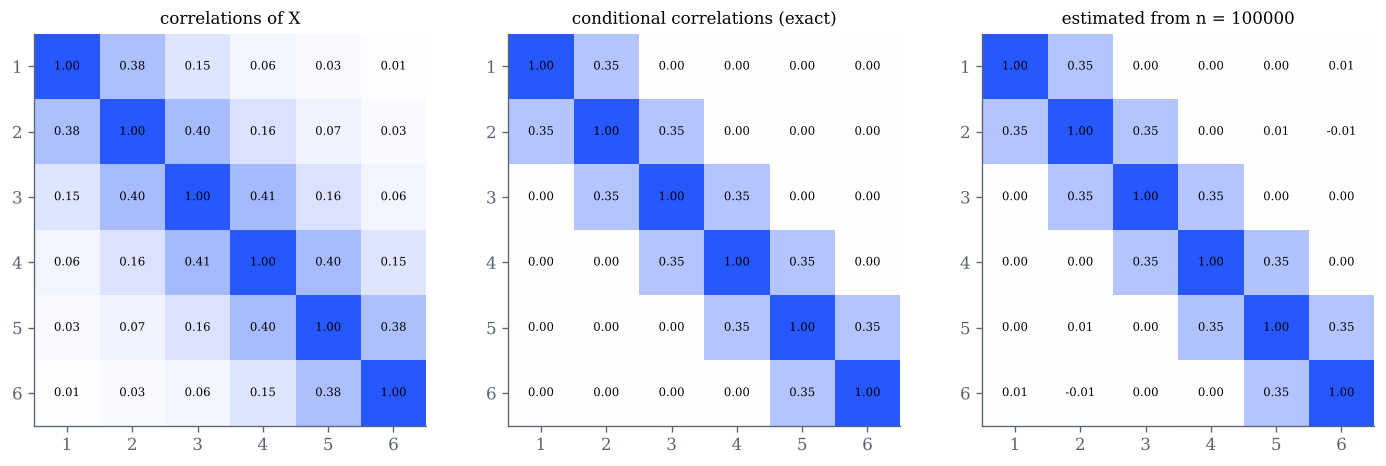

true edges:      [(1, 2), (2, 3), (3, 4), (4, 5), (5, 6)]
recovered edges: [(1, 2), (2, 3), (3, 4), (4, 5), (5, 6)]
zero correlations of X: 0


In [7]:
GRAPHS = {
    "chain": lambda d: [(i, i + 1) for i in range(d - 1)],
    "tree of Exercise 14.7": lambda d: [(0, 1), (1, 2), (2, 3), (1, 4)][: max(d - 1, 1)],
    "cycle": lambda d: [(i, (i + 1) % d) for i in range(d)],
    "star": lambda d: [(0, i) for i in range(1, d)],
}

def graph_demo(graph="chain", d=6, w=0.35, log10_n=5.0, seed=2026):
    if graph == "tree of Exercise 14.7":
        d = 5
    edges = GRAPHS[graph](d)
    P = np.eye(d)
    for i, j in edges:
        P[i, j] = P[j, i] = -w
    if np.linalg.eigvalsh(P).min() <= 1e-9:
        print(f"P is not positive definite for w = {w}: lower w")
        return
    C = np.linalg.inv(P)
    n = int(10 ** log10_n)
    x = sample_gaussian(None, C, n, seed=seed)
    Ch = np.cov(x, rowvar=False)
    R_true, R_est = partial_correlations(C), partial_correlations(Ch)
    corr = C / np.sqrt(np.outer(np.diag(C), np.diag(C)))
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, M, title in zip(axes, (corr, R_true, R_est),
                            ("correlations of X", "conditional correlations (exact)", f"estimated from n = {n}")):
        ax.imshow(M, cmap=CMAP, vmin=-1, vmax=1)
        for i in range(d):
            for j in range(d):
                ax.text(j, i, f"{M[i, j]:.2f}".replace("-0.00", "0.00"), ha="center", va="center", fontsize=7)
        ax.set_xticks(range(d), [str(i + 1) for i in range(d)])
        ax.set_yticks(range(d), [str(i + 1) for i in range(d)])
        ax.grid(False)
        ax.set_title(title)
    fig.tight_layout()
    plt.show()
    found = conditional_independence_graph(Ch, tol=3 / np.sqrt(n))
    true = sorted(tuple(sorted(e)) for e in edges)
    print("true edges:     ", [(i + 1, j + 1) for i, j in true])
    print("recovered edges:", [(i + 1, j + 1) for i, j in found])
    print("zero correlations of X:", int(np.sum(np.abs(corr[np.triu_indices(d, 1)]) < 1e-12)))

graph_demo()

In [8]:
# Explore: lower n until the recovered graph has errors; raise w towards the edge of positive definiteness.
interact(graph_demo,
         graph=Dropdown(options=list(GRAPHS), value="chain", description="graph"),
         d=IntSlider(value=6, min=3, max=10, continuous_update=False, description="dimension"),
         w=FloatSlider(value=0.35, min=0.05, max=0.6, step=0.01, continuous_update=False, description="weight w"),
         log10_n=FloatSlider(value=5.0, min=2.5, max=6.0, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $\rho=0$: the slab histogram is the law of $X$ whatever $y_0$ (Remark 14.2). Set $\rho=0.99$: the conditional law is very narrow, and a slab of half-width $0.05$ is no longer thin compared with it. What happens to the slab variance, and why?
- In section 1, widen the slab to $h=1$: the slab average of $X$ moves away from $m(y_0)$ but stays on $m$ at the slab average of $Y$. Why is the second comparison exact?
- In section 2, pin only the middle value: what is the conditional law of the second half of the path, and why does it not depend on the first half?
- In section 2, compare the conditional variance at $k$ for the bridge with $k(N-k)/N$ (Exercise 14.8).
- In section 3, choose the cycle with $d=6$: every pair of components is correlated, yet each component is conditionally independent of the three it is not connected to. How large must $n$ be for the recovered graph to be right with $w=0.1$?